# 71장 · 같은 API를 Docker 이미지로 옮기기

같은 API 이미지를 두 번 실행했다고 해서 먼저 띄운 컨테이너가 다시 시작된 것은 아닙니다. 이미지가 어떤 프로세스를 실행하게 되어 있는지 Dockerfile에서 읽고, 준비된 수업 환경에서는 한 컨테이너의 ID를 유지하며 상태를 관찰합니다.

실행을 확인한 커널은 Python 3.12.15입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 과제 셀에 직접 코드를 작성한 뒤 바로 아래에서 풀이를 펼쳐 보세요.

## 이미지가 실행할 첫 프로세스 읽기

Dockerfile의 RUN은 이미지를 만들 때 필요한 명령입니다. CMD는 그 이미지에서 컨테이너를 시작할 때 실행할 기본 명령입니다. EXPOSE는 컨테이너가 사용하는 포트를 설명합니다. 호스트에서 접속할 포트의 공개 설정은 별개입니다.

<!-- motion:image-imprint -->
**이미지에 적힌 CMD는 언제 실행될까요?**

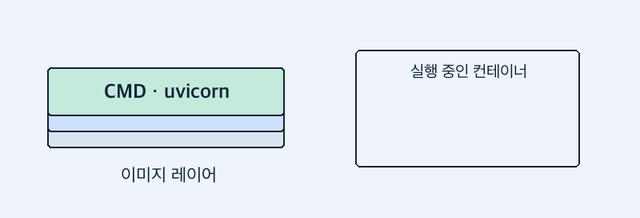

이미지는 시작 명령을 보관합니다. 컨테이너를 시작하면 그 명령으로 프로세스가 생깁니다. 이 그림은 원리 설명이며 실제 Docker 실행 여부는 셀 출력에서 확인합니다.
<!-- /motion -->


### 셀 01 · 원본 Dockerfile에서 CMD 읽기

71장 입문 이미지의 Dockerfile에서 마지막 CMD 줄을 가져왔습니다. JSON 배열을 읽어 프로그램과 포트를 나눠 보세요.

In [1]:
import json
directive = 'CMD ["python", "-m", "uvicorn", "main:app", "--host", "0.0.0.0", "--port", "8000"]'
argv = json.loads(directive.removeprefix("CMD "))
print(argv[:4], argv[-1])

['python', '-m', 'uvicorn', 'main:app'] 8000


python -m uvicorn main:app가 8000번 포트에서 실행됩니다. Dockerfile을 읽은 단계에서는 프로세스나 컨테이너가 아직 만들어지지 않았습니다.

### 과제 02 · 빌드할 때만 필요한 줄 찾기

아래 줄 중 의존성을 이미지에 설치하는 지시문 한 줄을 찾으세요.

In [2]:
steps = ['COPY requirements.txt ./', 'RUN python -m pip install -r requirements.txt', 'EXPOSE 8000']
# RUN으로 시작하는 줄을 찾으세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>steps = [&#x27;COPY requirements.txt ./&#x27;, &#x27;RUN python -m pip install -r requirements.txt&#x27;, &#x27;EXPOSE 8000&#x27;]
print(next(step for step in steps if step.startswith(&#x27;RUN &#x27;)))</code></pre>
<p>실행 결과</p><pre><code>RUN python -m pip install -r requirements.txt</code></pre>
<p>이미지를 빌드할 때 설치하므로 같은 이미지의 컨테이너를 다시 시작할 때마다 의존성을 설치하지 않습니다.</p>
</details>

## 같은 컨테이너를 중지하고 다시 시작하기

강사가 Docker 엔진과 수업용 이미지를 미리 준비한 경우에만 아래 선택 셀의 image_id에 제공받은 로컬 이미지 ID를 넣으세요. 새 컨테이너 하나를 포트 공개 없이 만들고 네트워크를 끈 상태에서 확인한 뒤 그 컨테이너만 정리합니다. 기본값은 Docker를 호출하지 않습니다.


### 셀 03 · 선택 실습 · Docker 엔진에서 상태 읽기

강사가 제공한 이미지 안에서 Python 대기 프로세스를 실행할 수 있어야 합니다. create는 객체만 만들고, start와 stop은 같은 ID를 대상으로 합니다.

여기서는 API 대신 대기 프로세스를 띄워 컨테이너가 실행 상태를 유지하는지 봅니다. 컨테이너가 실행 중이어도 요청에 답하는지는 아직 모릅니다. API를 올렸을 때는 질문을 보내 상태 코드와 응답을 따로 확인하세요.

In [3]:
import subprocess
image_id = ""  # 준비된 수업용 Python 이미지의 로컬 ID
def docker(*args):
    return subprocess.run(["docker", *args], check=True, capture_output=True, text=True, timeout=40).stdout.strip()

if image_id:
    docker("image", "inspect", image_id)
    cid = docker("create", "--pull", "never", "--network", "none", image_id,
                 "python", "-c", "import time; time.sleep(120)")
    try:
        docker("start", cid)
        print(docker("inspect", "--format", "{{.State.Status}}", cid))
        docker("stop", "--time", "1", cid)
        print(docker("inspect", "--format", "{{.State.Status}}", cid))
        docker("start", cid)
        print(docker("inspect", "--format", "{{.State.Status}}", cid))
    finally:
        docker("rm", "-f", cid)
else:
    print("수업용 로컬 이미지 ID가 없어 컨테이너 실습을 건너뜁니다.")

수업용 로컬 이미지 ID가 없어 컨테이너 실습을 건너뜁니다.


기본값이면 이미지가 준비되지 않았다는 안내만 나옵니다. 엔진에서 실행했을 때 확인할 상태는 running, exited, running입니다. 매번 같은 cid를 inspect하므로 ‘새 컨테이너를 하나 더 만들었다’는 설명과 구분할 수 있습니다. 수업에서는 강사가 로컬에 준비한 Python 이미지 ID를 image_id에 넣습니다. 차례로 running, exited, running이 나와야 같은 컨테이너의 정지와 재시작을 관찰한 것입니다.

## 돌아보기

새 이미지로 교체해야 할 상황과 기존 컨테이너를 다시 시작해도 되는 상황을 한 가지씩 골라 보세요. 이번 셀에서 본 ID는 다음 장의 DB 볼륨 이름과도 다릅니다.

### 한 파일 변경이 실행에 반영되는 경로

**파일 수정**　호스트 application의 코드를 수정합니다. 기존 이미지에는 아직 반영되지 않습니다.

```
호스트 파일
```

**새 이미지 생성**　Dockerfile과 컨텍스트로 새 이미지를 만듭니다. 실제 성공은 build 결과로 확인합니다.

```
새 image ID
```

**새 컨테이너 생성**　선택한 이미지와 환경으로 컨테이너를 만듭니다. 기존 컨테이너 restart와 다릅니다.

```
새 container ID
```

**같은 질문 대조**　정상·실패·전체 출처를 같은 기준으로 확인합니다.

```
같은 질문으로 답과 출처를 다시 확인
```
